# Function 2: Black-box optimisation

This notebook documents 13 rounds of model fitting, candidate selection and evaluated outputs for Function 2. Alternative approaches are retained where they informed the weekly decisions.

**Main result:** The best output was 0.670534 in Week 12; later ensemble predictions were less reliable.

**Usage:** Run the setup and then the weekly sections in order. The initial datasets are in this folder; the full query history is in [`weekly_submissions.csv`](../submissions/weekly_submissions.csv). Some early searches generate large candidate grids and may require substantial memory.

In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, RBF, WhiteKernel


def resolve_initial_path(filename: str) -> Path:
    """Find the initial dataset for Function 2."""
    for folder in (Path.cwd(), Path.cwd() / "function_2"):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"{filename} not found. Place it in the function_2/ folder."
    )

## Reusable routines

The helper functions below handle standard GP fitting, UCB scoring and recording evaluated queries. The model settings and experiments remain visible within each week.

In [ ]:
def fit_gp_model(X, y, **settings):
    """Fit a GP using the explicit kernel and settings chosen for a given week."""
    gp = GaussianProcessRegressor(**settings)
    gp.fit(X, y)
    return gp


def ucb_score(mean, std, beta):
    """Upper Confidence Bound: predictive mean plus weighted uncertainty."""
    return mean + beta * std


def add_evaluation(X, y, x_observed, y_observed):
    """Add one completed black-box evaluation to the training history."""
    x_row = np.asarray(x_observed, dtype=float).reshape(1, -1)
    y_value = np.asarray(y_observed, dtype=float).reshape(1)
    if x_row.shape[1] != X.shape[1]:
        raise ValueError("The evaluated input has the wrong number of dimensions.")
    return np.vstack([X, x_row]), np.concatenate([y, y_value])


### GP surface visualisations

In [ ]:
def plot_2d_surface(
    X1_grid,
    X2_grid,
    values,
    X_obs,
    candidate,
    *,
    title,
    colorbar_label,
    candidate_label="Next UCB query",
):
    """Plot one two-dimensional surface and highlight the observations and query."""
    surface = np.asarray(values).reshape(X1_grid.shape)
    fig, ax = plt.subplots(figsize=(10, 6))

    contours = ax.contourf(X1_grid, X2_grid, surface, levels=20)
    fig.colorbar(contours, ax=ax, label=colorbar_label)

    ax.scatter(
        X_obs[:, 0], X_obs[:, 1],
        marker="x", s=100, label="Existing observations"
    )
    ax.scatter(
        candidate[0], candidate[1],
        marker="*", s=200, label=candidate_label
    )

    ax.set(xlabel="X1", ylabel="X2", title=title)
    ax.legend()
    plt.show()


def plot_gp_diagnostics_2d(
    X1_grid, X2_grid, post_mean, post_std, ucb, X_obs, candidate
):
    """Plot the GP posterior mean, uncertainty and UCB acquisition surface."""
    diagnostics = (
        (post_mean, "Gaussian Process Posterior Mean", "GP predicted mean", "Next UCB query"),
        (post_std, "Gaussian Process Uncertainty", "GP standard deviation", "Next UCB query"),
        (ucb, "UCB Acquisition Function", "UCB", "Highest UCB"),
    )
    for values, title, colorbar_label, candidate_label in diagnostics:
        plot_2d_surface(
            X1_grid,
            X2_grid,
            values,
            X_obs,
            candidate,
            title=title,
            colorbar_label=colorbar_label,
            candidate_label=candidate_label,
        )


## Starting data

In [2]:
X = np.load(resolve_initial_path("initial_inputs.npy"))
y = np.load(resolve_initial_path("initial_outputs.npy"))

## Week 1

Next input combination suggested by UCB:
[0.7997998  0.91991992]

Predicted mean:
0.5356829673702482

Predicted standard deviation:
0.16530289267738071

UCB:
0.8596766370179144


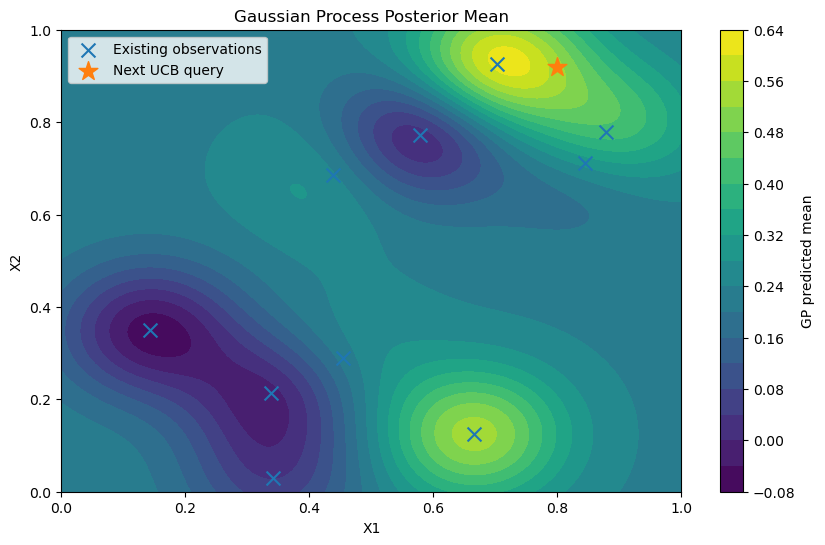

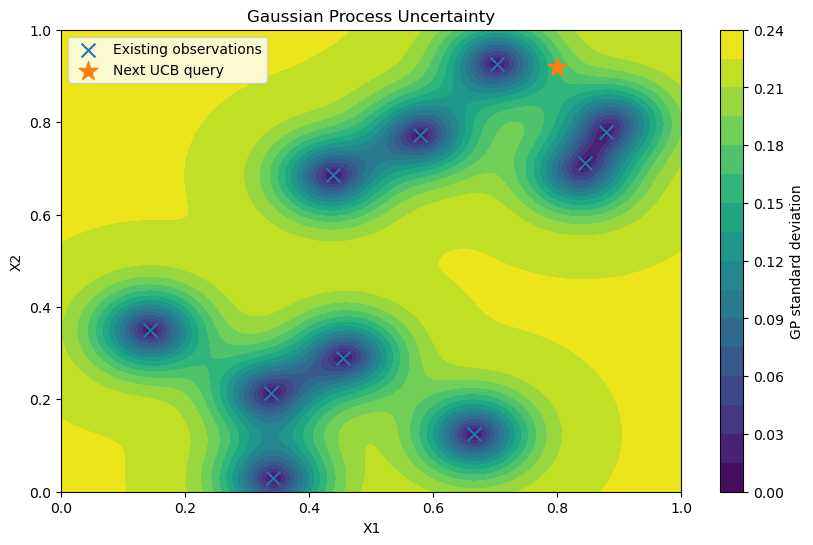

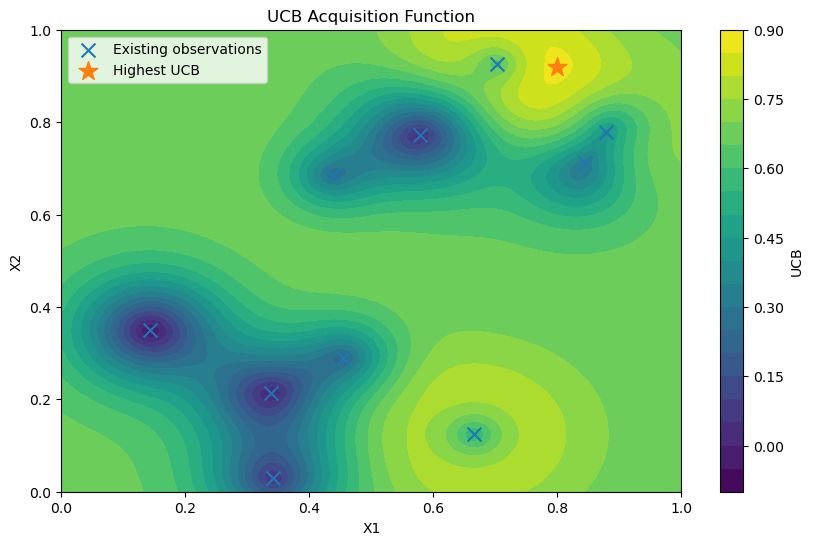

In [6]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = 0.1

# UCB exploration parameter
beta = 1.96
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds="fixed"
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True
)
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 1000)
x2_values = np.linspace(0, 1, 1000)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Evaluated query

**Input:** `(0.799800, 0.919920)`  
**Output:** `0.04307873352190652`

In [ ]:
X_week1 = np.array([0.7998, 0.91992])
y_week1 = np.array([0.04307873352190652])
X_new, y_new = add_evaluation(X, y, X_week1, y_week1)

## Week 2

In [10]:
X = X_new
y = y_new

### Increase β to favour exploration

In [11]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = 0.1

beta = 3

### Allow the kernel length scale to vary

In [12]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.1, 1.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=0.1)

Optimised kernel:
RBF(length_scale=0.1)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.1. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


### Increase candidate-grid resolution

In [13]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

In [14]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)

In [15]:
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

Next input combination suggested by UCB:
[0.6182 0.9932]

Predicted mean:
0.6017378180032974

Predicted standard deviation:
0.17385930571318933

UCB:
1.1233157351428655


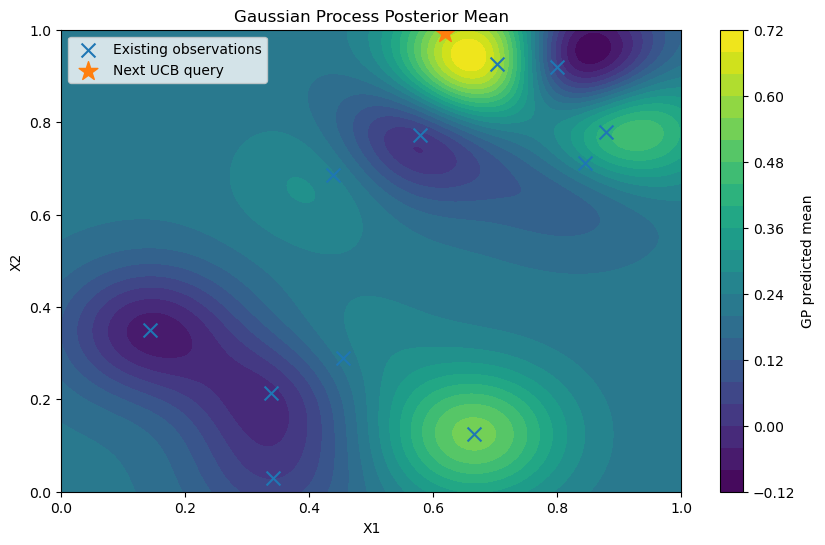

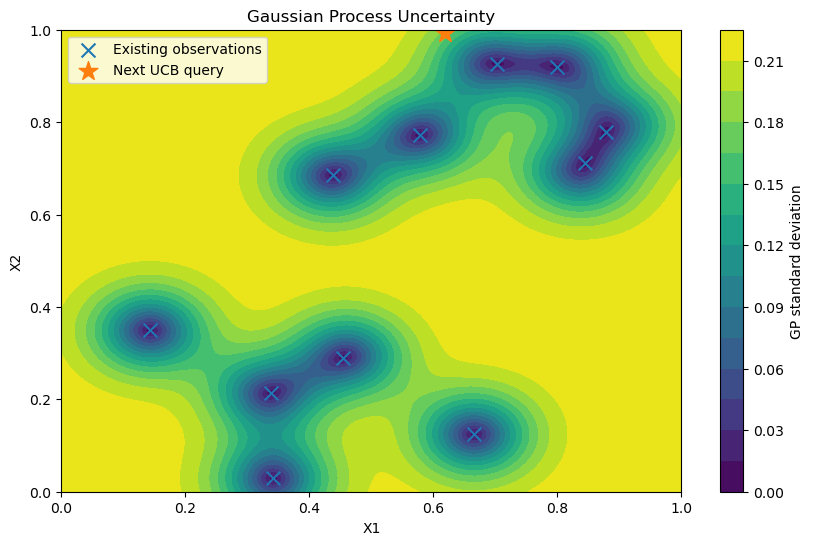

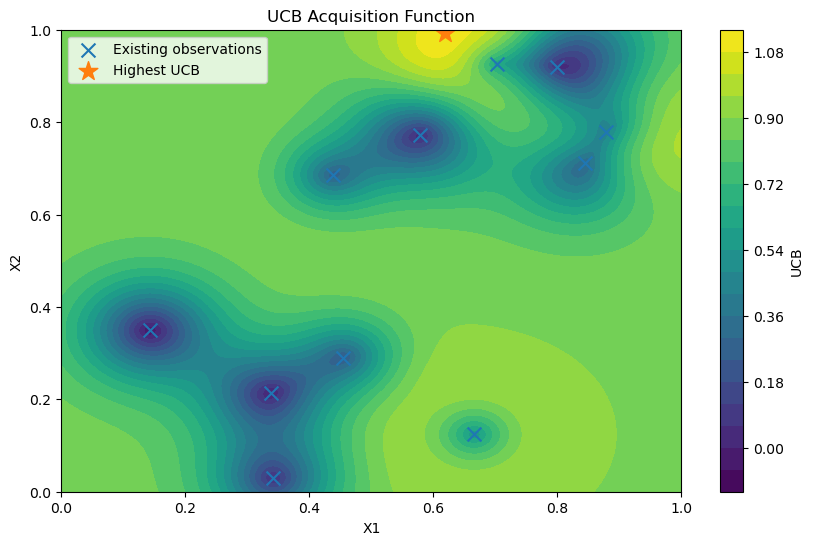

In [16]:
plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Evaluated query

**Input:** `(0.618200, 0.993200)`  
**Output:** `0.22251859346757985`

In [ ]:
X_week2 = np.array([0.6182, 0.9932])
y_week2 = np.array([0.22251859346757985])
X_new, y_new = add_evaluation(X, y, X_week2, y_week2)

## Week 3

In [20]:
X = X_new
y = y_new

### Retain β = 3 for exploration

In [21]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = 0.1

beta = 3

### Retain kernel length-scale bounds of 0.1–1

In [22]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.1, 1.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=0.1)

Optimised kernel:
RBF(length_scale=0.1)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.1. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [23]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

Next input combination suggested by UCB:
[1.     0.7546]

Predicted mean:
0.39721005120683156

Predicted standard deviation:
0.18490272131134342

UCB:
0.9519182151408618


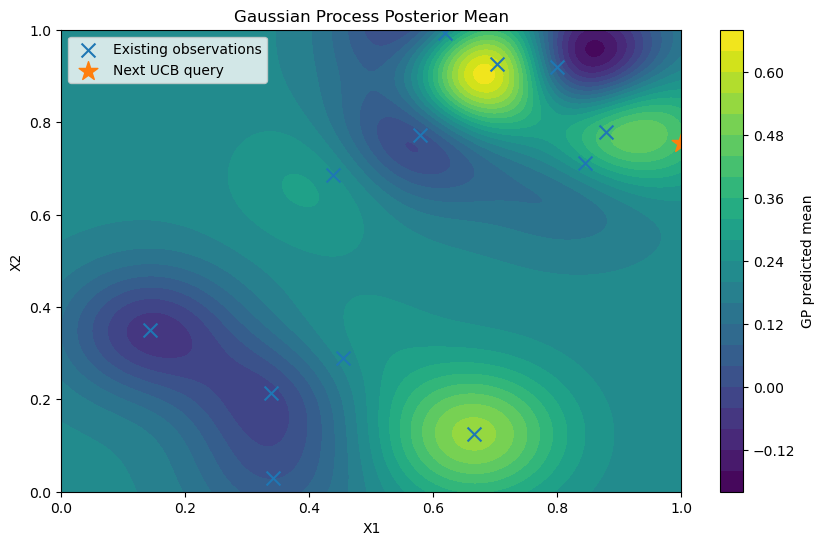

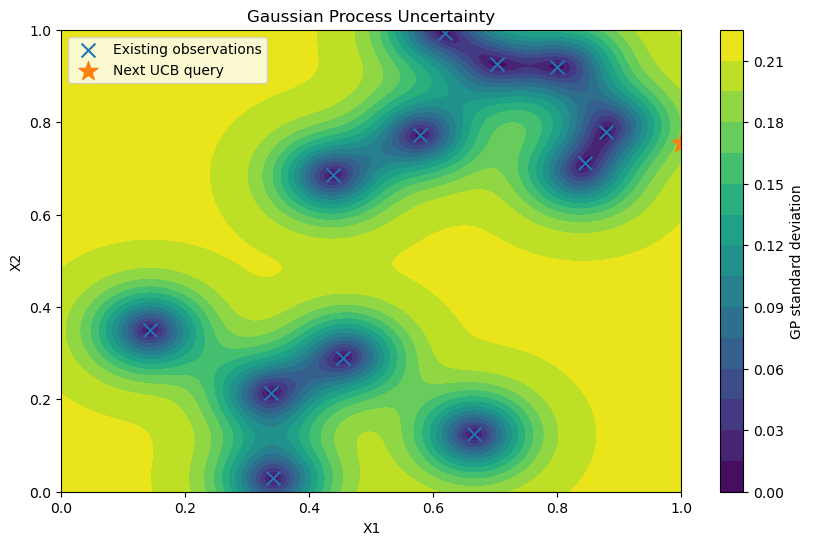

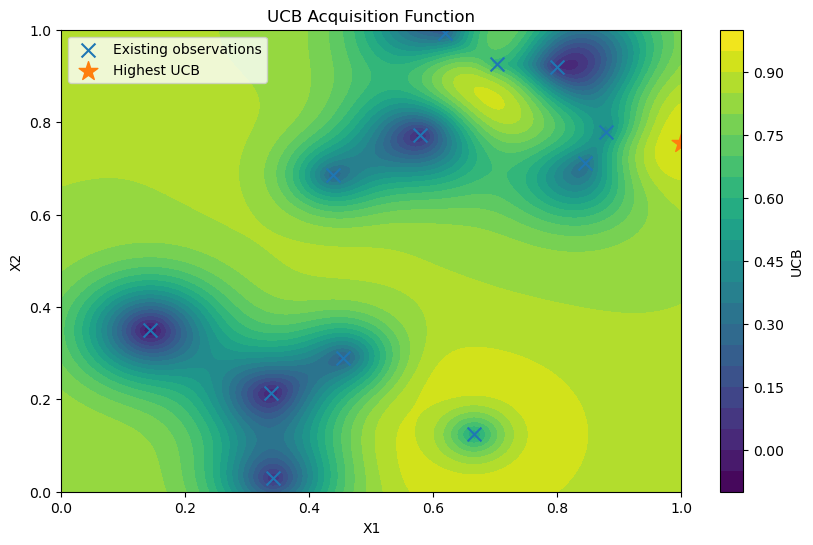

In [24]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Maximum-distance candidate

In [25]:
distances = cdist(X_grid, X)

nearest_distance = distances.min(axis=1)

farthest_index = np.argmax(nearest_distance)

most_unexplored_X = X_grid[farthest_index]

print(most_unexplored_X)
print(nearest_distance[farthest_index])

[0. 1.]
0.5396322785914337


### Anisotropic GP with separate feature length scales · selected

In [26]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = [0.1, 0.1]

beta = 2.5

In [27]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.01, 2.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=[0.1, 0.1])

Optimised kernel:
RBF(length_scale=[0.0476, 1.3])


In [28]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

Next input combination suggested by UCB:
[0.7122 0.    ]

Predicted mean:
0.518836321200719

Predicted standard deviation:
0.12430604048354466

UCB:
0.8296014224095807


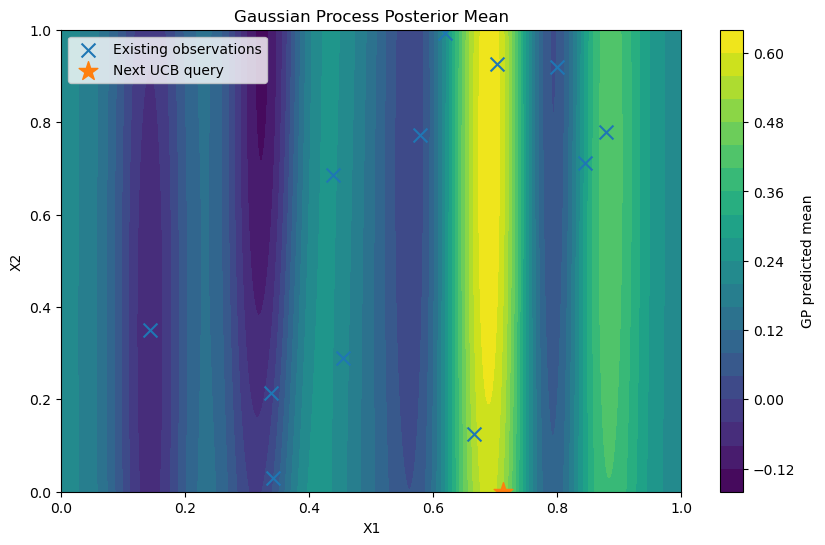

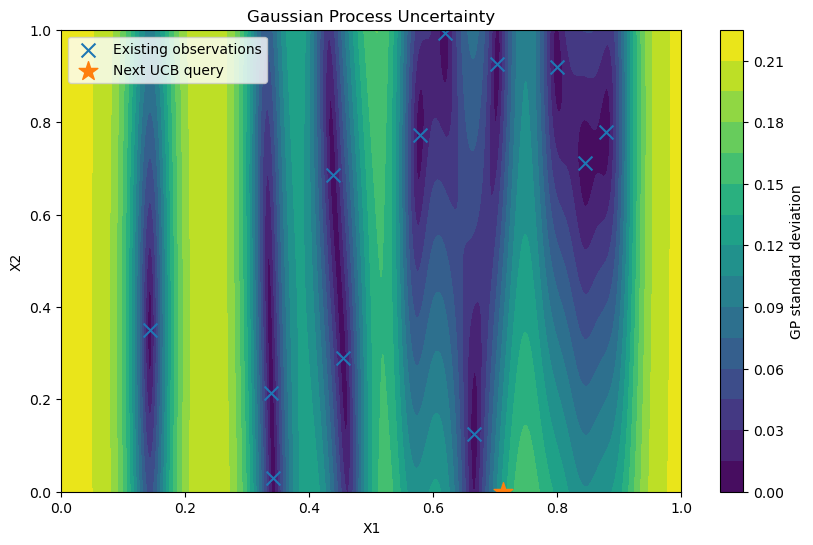

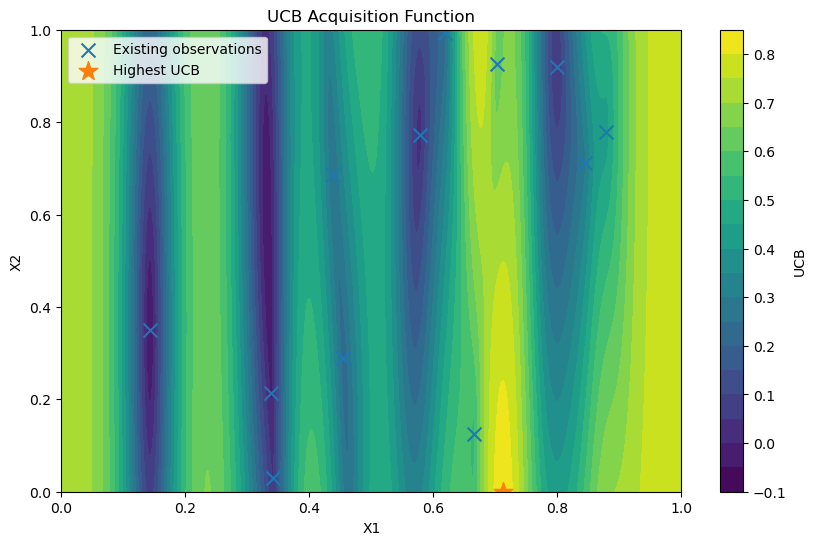

In [29]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Evaluated query

**Input:** `(0.712200, 0.000000)`  
**Output:** `0.4645371131917123`

In [ ]:
X_week3 = np.array([0.7122, 0.])
y_week3 = np.array([0.4645371131917123])
X_new, y_new = add_evaluation(X, y, X_week3, y_week3)

## Week 4

In [33]:
X = X_new
y = y_new

In [34]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = [0.1, 0.1]

beta = 1.5

In [35]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.01, 2.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=[0.1, 0.1])

Optimised kernel:
RBF(length_scale=[0.0493, 1.36])


In [36]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

Next input combination suggested by UCB:
[0.6794 1.    ]

Predicted mean:
0.6308125681013921

Predicted standard deviation:
0.05108094406624951

UCB:
0.7074339842007663


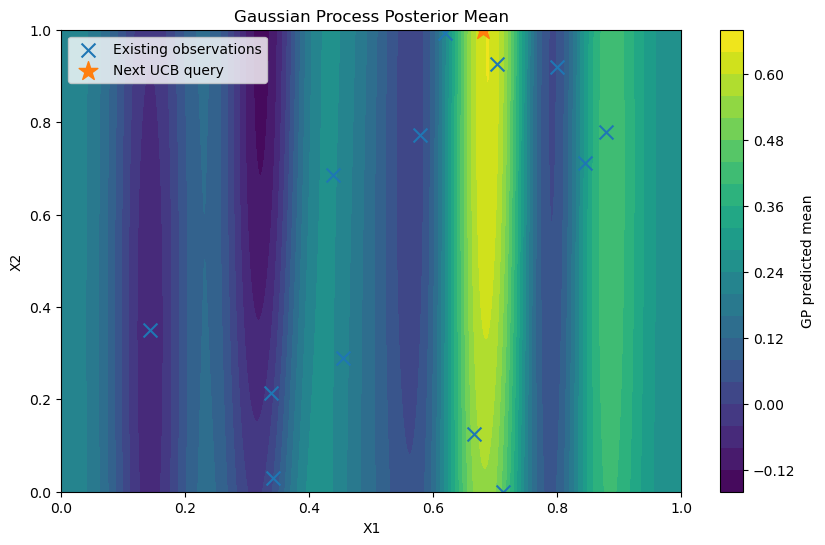

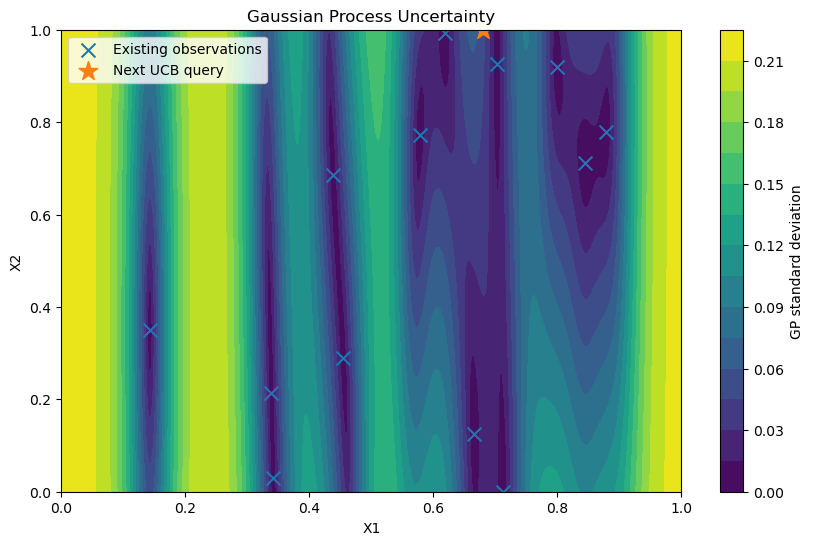

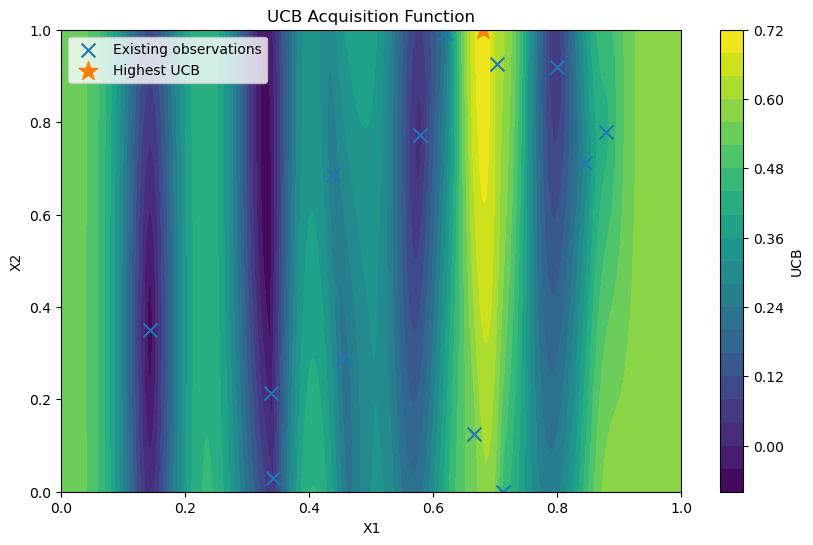

In [37]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Evaluated query

**Input:** `(0.679400, 1.000000)`  
**Output:** `0.6238488085791416`

In [ ]:
X_week4 = np.array([0.6794, 1.])
y_week4 = np.array([0.6238488085791416])
X_new, y_new = add_evaluation(X, y, X_week4, y_week4)

## Week 5

In [41]:
X = X_new
y = y_new

In [42]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = [0.1, 0.1]

beta = 1

In [43]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.01, 2.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=[0.1, 0.1])

Optimised kernel:
RBF(length_scale=[0.0552, 1.56])


In [44]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

Next input combination suggested by UCB:
[0.688  0.8048]

Predicted mean:
0.6312853229785911

Predicted standard deviation:
0.009946628959343524

UCB:
0.6412319519379346


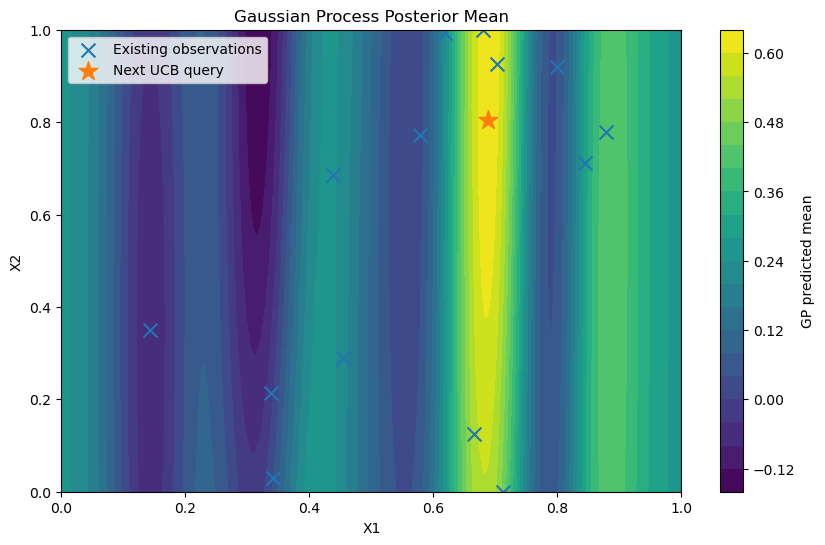

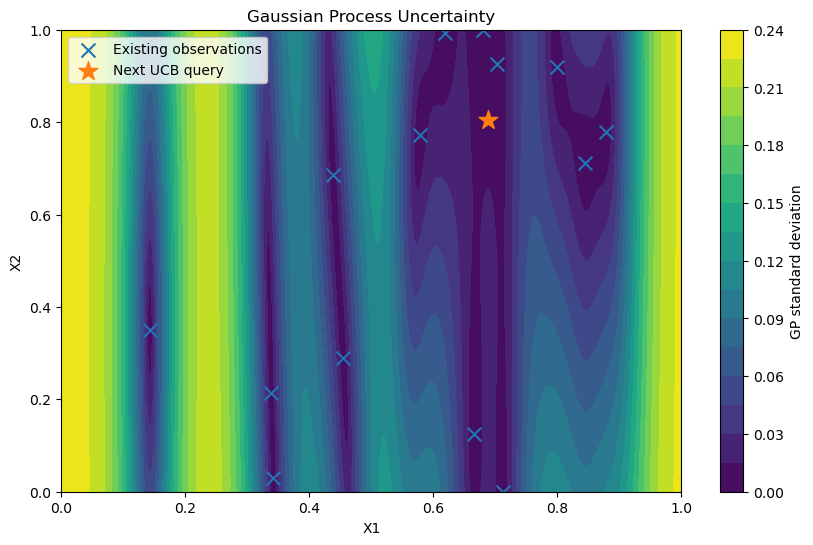

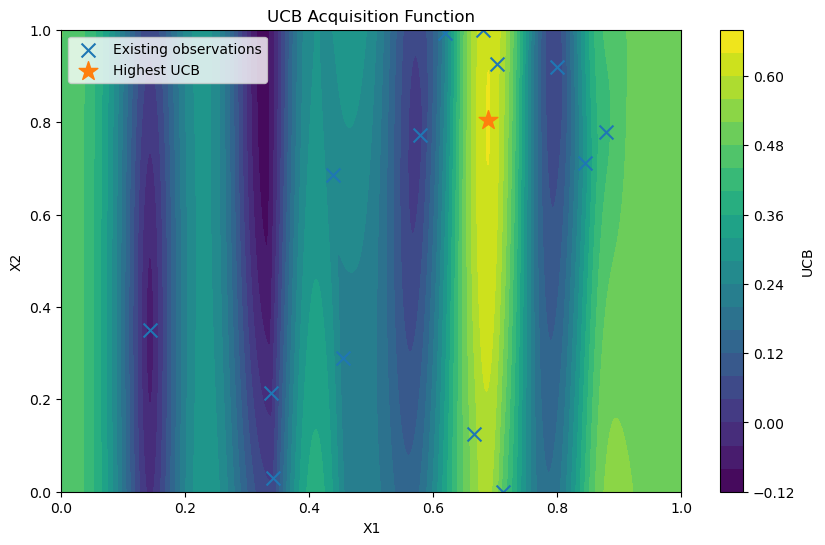

In [45]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Evaluated query

**Input:** `(0.688000, 0.804800)`  
**Output:** `0.5514104809990639`

In [ ]:
X_week5 = np.array([0.688, 0.8048])
y_week5 = np.array([0.5514104809990639])
X_new, y_new = add_evaluation(X, y, X_week5, y_week5)

## Week 6

In [49]:
X = X_new
y = y_new

### Anisotropic Matérn 3/2 kernel

In [50]:
# Week 6 GP parameters
beta = 1.0

kernel = Matern(
    length_scale=[0.1, 0.1],
    length_scale_bounds=(0.01, 5.0),
    nu=1.5
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Optimised kernel:", model.kernel_)

# Generate global candidate grid
values = np.linspace(0, 1, 1001)

X1_grid, X2_grid = np.meshgrid(values, values)

X_candidates = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

# GP predictions
post_mean, post_std = model.predict(
    X_candidates,
    return_std=True
)

# Acquisition function
UCB = ucb_score(post_mean, post_std, beta)

# Optional: enforce minimum distance from prior observations
tree = cKDTree(X)
distances, _ = tree.query(X_candidates)

min_distance = 0.05
UCB[distances < min_distance] = -np.inf

# Select Week 6 query
best_index = np.argmax(UCB)
next_X = X_candidates[best_index]

print("Week 6 candidate:", np.round(next_X, 6))
print("Predicted mean:", post_mean[best_index])
print("Predicted std:", post_std[best_index])
print("UCB:", UCB[best_index])

Optimised kernel: Matern(length_scale=[0.0444, 2.37], nu=1.5)
Week 6 candidate: [0.666 0.892]
Predicted mean: 0.6135739968983254
Predicted std: 0.061085009095942555
UCB: 0.6746590059942679


### Evaluated query

**Input:** `(0.666000, 0.892000)`  
**Output:** `0.4365070548548307`

In [ ]:
X_week6 = np.array([0.666, 0.892])
y_week6 = np.array([0.4365070548548307])
X_new, y_new = add_evaluation(X, y, X_week6, y_week6)

## Week 7

In [54]:
X = X_new
y = y_new

In [55]:
# Use all 16 observations, including Week 6
X = X_new
y = y_new

assert X.shape == (16, 2)
assert y.shape == (16,)

# Tuned GP model
kernel = (
    RBF(
        length_scale=[0.1, 0.3],
        length_scale_bounds=(0.015, 10.0)
    )
    + WhiteKernel(
        noise_level=0.02,
        noise_level_bounds=(1e-5, 0.4)
    )
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=6,
    random_state=42
)

print("Optimised kernel:", model.kernel_)

# Generate candidate grid
values = np.linspace(0, 1, 501)
X1_grid, X2_grid = np.meshgrid(values, values)

X_candidates = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

# Obtain predictions in batches
post_mean = np.empty(len(X_candidates))
post_std = np.empty(len(X_candidates))

for start in range(0, len(X_candidates), 20000):
    end = min(start + 20000, len(X_candidates))

    mu, sigma = model.predict(
        X_candidates[start:end],
        return_std=True
    )

    post_mean[start:end] = mu
    post_std[start:end] = sigma

# Remove the WhiteKernel noise contribution from
# predictive variance for latent-function exploration
noise_variance = (
    model.kernel_.k2.noise_level * np.var(y)
)

latent_std = np.sqrt(
    np.maximum(post_std**2 - noise_variance, 0)
)

# GP-UCB acquisition
beta = 1.0
UCB = ucb_score(post_mean, latent_std, beta)

# Permit local refinement without repeated queries
min_distance = 0.03
distances = cKDTree(X).query(X_candidates)[0]

UCB[distances < min_distance] = -np.inf

# Select candidate
best_index = np.argmax(UCB)
next_X = X_candidates[best_index]

print("Week 7 candidate:", next_X)
print("Predicted mean:", post_mean[best_index])
print("Latent predictive std:", latent_std[best_index])
print("UCB:", UCB[best_index])
print("Nearest distance:", distances[best_index])

Optimised kernel: RBF(length_scale=[0.0559, 10]) + WhiteKernel(noise_level=0.056)
Week 7 candidate: [0.69 0.97]
Predicted mean: 0.5715193337924344
Latent predictive std: 0.026409824308190274
UCB: 0.5979291581006246
Nearest distance: 0.03181760518958023


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


### Evaluated query

**Input:** `(0.690000, 0.970000)`  
**Output:** `0.4907390429897661`

In [ ]:
X_week7 = np.array([0.69, 0.97])
y_week7 = np.array([0.4907390429897661])
X_new, y_new = add_evaluation(X, y, X_week7, y_week7)

## Week 8

In [59]:
# All observations through Week 7
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (17, 2)
assert y.shape == (17,)

# Regularised anisotropic GP
kernel = (
    RBF(
        length_scale=[0.1, 0.4],
        length_scale_bounds=(0.015, 10.0)
    )
    + WhiteKernel(
        noise_level=0.02,
        noise_level_bounds=(1e-5, 0.4)
    )
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=6,
    random_state=42
)
print("Optimised kernel:", model.kernel_)

# Candidate grid
values = np.linspace(0, 1, 501)
x1_grid, x2_grid = np.meshgrid(values, values)

candidates = np.column_stack([
    x1_grid.ravel(),
    x2_grid.ravel()
])

mu_all = np.empty(len(candidates))
std_all = np.empty(len(candidates))

for start in range(0, len(candidates), 20000):
    end = min(start + 20000, len(candidates))
    mu, std = model.predict(
        candidates[start:end],
        return_std=True
    )
    mu_all[start:end] = mu
    std_all[start:end] = std

# Exclude fitted observation noise from the
# acquisition uncertainty
noise_variance = (
    model.kernel_.k2.noise_level * np.var(y)
)

latent_std = np.sqrt(
    np.maximum(std_all**2 - noise_variance, 0)
)

# GP-UCB
beta = 1.0
ucb = ucb_score(mu_all, latent_std, beta)

distances = cKDTree(X).query(candidates)[0]
min_distance = 0.03
ucb[distances < min_distance] = -np.inf

best_idx = np.argmax(ucb)
next_X = candidates[best_idx]

print("Week 8 query:", next_X)
print("Predicted mean:", mu_all[best_idx])
print("Latent std:", latent_std[best_idx])
print("UCB:", ucb[best_idx])
print("Nearest distance:", distances[best_idx])

Optimised kernel: RBF(length_scale=[0.057, 10]) + WhiteKernel(noise_level=0.0654)
Week 8 query: [0.688 0.018]
Predicted mean: 0.5531740441694825
Latent std: 0.02849578403894512
UCB: 0.5816698282084276
Nearest distance: 0.030160238725845657


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


### Evaluated query

**Input:** `(0.688000, 0.018000)`  
**Output:** `0.5696730471858912`

In [ ]:
X_week8 = np.array([0.688, 0.018])
y_week8 = np.array([0.5696730471858912])
X_new, y_new = add_evaluation(X, y, X_week8, y_week8)

## Week 9

In [63]:
# All observations through Week 8
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (18, 2)
assert y.shape == (18,)

# Selected regularised anisotropic GP
kernel = (
    RBF(
        length_scale=[0.1, 0.5],
        length_scale_bounds=(0.01, 10.0)
    )
    + WhiteKernel(
        noise_level=0.05,
        noise_level_bounds=(1e-5, 0.5)
    )
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)
print("Optimised kernel:", model.kernel_)

# Search a dense two-dimensional grid
values = np.linspace(0, 1, 1001)
x1_grid, x2_grid = np.meshgrid(values, values)

candidates = np.column_stack([
    x1_grid.ravel(),
    x2_grid.ravel()
])

beta = 1.0
min_distance = 0.10

# Predictive observation noise on original scale
noise_variance = (
    model.kernel_.k2.noise_level * np.var(y)
)

ucb = np.empty(len(candidates))
means = np.empty(len(candidates))
latent_stds = np.empty(len(candidates))

# Process in batches to avoid excessive memory use
for start in range(0, len(candidates), 20000):
    end = min(start + 20000, len(candidates))

    mu, total_std = model.predict(
        candidates[start:end],
        return_std=True
    )

    latent_std = np.sqrt(
        np.maximum(total_std**2 - noise_variance, 0)
    )

    means[start:end] = mu
    latent_stds[start:end] = latent_std
    ucb[start:end] = ucb_score(mu, latent_std, beta)

# Exclude locations too close to existing points
distances = cKDTree(X).query(candidates)[0]
ucb[distances < min_distance] = -np.inf

best_idx = np.argmax(ucb)
next_X = candidates[best_idx]

print("Week 9 query:", next_X)
print("Predicted mean:", means[best_idx])
print("Latent std:", latent_stds[best_idx])
print("UCB:", ucb[best_idx])
print("Nearest distance:", distances[best_idx])
print("Current best:", y.max())

/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Optimised kernel: RBF(length_scale=[0.0577, 10]) + WhiteKernel(noise_level=0.0578)
Week 9 query: [0.688 0.222]
Predicted mean: 0.5571768728640526
Latent std: 0.022767894883355344
UCB: 0.5799447677474079
Nearest distance: 0.10051323582655247
Current best: 0.6238488085791416


### Evaluated query

**Input:** `(0.688000, 0.222000)`  
**Output:** `0.5514661964990325`

In [ ]:
X_week9 = np.array([0.688, 0.222])
y_week9 = np.array([0.5514661964990325])
X_new, y_new = add_evaluation(X, y, X_week9, y_week9)

## Week 10

In [67]:
# Observations through Week 9
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (19, 2)
assert y.shape == (19,)
# Fit the selected GP
kernel = (
    RBF(
        length_scale=[0.06, 3.0],
        length_scale_bounds=(0.02, 10.0)
    )
    + WhiteKernel(
        noise_level=0.05,
        noise_level_bounds=(1e-5, 0.5)
    )
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Optimised kernel:", model.kernel_)
# Build the candidate grid
values = np.linspace(0, 1, 1001)

grid_x1, grid_x2 = np.meshgrid(
    values, values
)

candidates = np.column_stack([
    grid_x1.ravel(),
    grid_x2.ravel()
])

tree = cKDTree(X)
distances = tree.query(candidates)[0]
# Predict latent mean and uncertainty
noise_variance = (
    model.kernel_.k2.noise_level
    * np.var(y)
)

means = np.empty(len(candidates))
stds = np.empty(len(candidates))

for start in range(0, len(candidates), 15000):

    end = min(
        start + 15000,
        len(candidates)
    )

    mu, total_std = model.predict(
        candidates[start:end],
        return_std=True
    )

    latent_std = np.sqrt(
        np.maximum(
            total_std**2 - noise_variance,
            0
        )
    )

    means[start:end] = mu
    stds[start:end] = latent_std
# Calculate GP-UCB
beta = 1.5
min_distance = 0.10

ucb = ucb_score(means, stds, beta)

# Exclude previously explored neighbourhoods
ucb[distances < min_distance] = -np.inf

maximum_ucb = np.max(ucb)

# -----------------------------------------
# Hybrid acquisition:
# Near-optimal UCB + spatial separation
# -----------------------------------------

# Retain points within 0.02% of best UCB
tolerance = 0.0002

eligible = (
    ucb >= maximum_ucb * (1 - tolerance)
)

distance_scores = np.where(
    eligible,
    distances,
    -np.inf
)

best_index = np.argmax(distance_scores)

next_X = candidates[best_index]
# Report results
print("Week 10 query:", next_X)
print("Predicted mean:", means[best_index])
print("Latent std:", stds[best_index])
print("GP-UCB:", ucb[best_index])
print(
    "Nearest observation distance:",
    distances[best_index]
)
print("Current best output:", y.max())

Optimised kernel: RBF(length_scale=[0.0583, 10]) + WhiteKernel(noise_level=0.0522)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Week 10 query: [0.973 0.4  ]
Predicted mean: 0.3633525920137816
Latent std: 0.21559362016006606
GP-UCB: 0.6867430222538806
Nearest observation distance: 0.3360193446812252
Current best output: 0.6238488085791416


### Evaluated query

**Input:** `(0.973000, 0.400000)`  
**Output:** `-0.017244813178750755`

In [ ]:
X_week10 = np.array([0.973, 0.4])
y_week10 = np.array([-0.017244813178750755])
X_new, y_new = add_evaluation(X, y, X_week10, y_week10)

## Week 11

In [70]:
# All observations through Week 10
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (20, 2)
assert y.shape == (20,)
# Fit the selected GP
kernel = (
    RBF(
        length_scale=[0.08, 0.4],
        length_scale_bounds=(0.015, 10.0)
    )
    + WhiteKernel(
        noise_level=0.03,
        noise_level_bounds=(1e-5, 0.5)
    )
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=8,
    random_state=42
)

print("Optimised kernel:", model.kernel_)
# Targeted search region
x1_values = np.linspace(0.62, 0.74, 481)
x2_values = np.linspace(0.30, 0.70, 401)

grid_x1, grid_x2 = np.meshgrid(
    x1_values, x2_values
)

candidates = np.column_stack([
    grid_x1.ravel(),
    grid_x2.ravel()
])

distances = cKDTree(X).query(candidates)[0]
# Predict latent mean and uncertainty
noise_variance = (
    model.kernel_.k2.noise_level * np.var(y)
)

means = np.empty(len(candidates))
stds = np.empty(len(candidates))

for start in range(0, len(candidates), 15000):

    end = min(start + 15000, len(candidates))

    mu, total_std = model.predict(
        candidates[start:end],
        return_std=True
    )

    means[start:end] = mu

    stds[start:end] = np.sqrt(
        np.maximum(total_std**2 - noise_variance, 0)
    )
# Targeted GP-UCB
beta = 1.0
min_distance = 0.20

ucb = ucb_score(means, stds, beta)
ucb[distances < min_distance] = -np.inf

best_index = np.argmax(ucb)

next_X = np.round(candidates[best_index], 6)
# Report candidate
print("\nWeek 11 proposed input:", next_X)
print("Predicted mean:", means[best_index])
print("Latent std:", stds[best_index])
print("UCB:", ucb[best_index])
print("Nearest distance:", distances[best_index])
print("Current best output:", np.max(y))

Optimised kernel: RBF(length_scale=[0.0554, 10]) + WhiteKernel(noise_level=0.0495)

Week 11 proposed input: [0.689 0.586]
Predicted mean: 0.5576437560204016
Latent std: 0.01923651063781361
UCB: 0.5768802666582152
Nearest distance: 0.20019263403273457
Current best output: 0.6238488085791416


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


### Evaluated query

**Input:** `(0.689000, 0.586000)`  
**Output:** `0.44660025767222666`

In [ ]:
X_week11 = np.array([0.689, 0.586])
y_week11 = np.array([0.44660025767222666])
X_new, y_new = add_evaluation(X, y, X_week11, y_week11)

## Week 12

In [73]:
# Observations through Week 11
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (21, 2)
assert y.shape == (21,)

best_idx = np.argmax(y)
best_X = X[best_idx]
best_y = y[best_idx]

print("Current best input:", best_X)
print("Current best output:", best_y)
# Define complementary GP kernels
kernels = {
    "RBF + WhiteKernel": (
        RBF([0.07, 0.4], (0.01, 6.0))
        + WhiteKernel(0.04, (1e-6, 0.3))
    ),
    "Matern 3/2 + WhiteKernel": (
        Matern([0.07, 0.4], (0.01, 6.0), nu=1.5)
        + WhiteKernel(0.04, (1e-6, 0.3))
    ),
    "Matern 5/2 + WhiteKernel": (
        Matern([0.07, 0.4], (0.01, 6.0), nu=2.5)
        + WhiteKernel(0.04, (1e-6, 0.3))
    ),
    "RBF": RBF(
        [0.05, 0.1],
        (0.01, 3.0)
    ),
    "Matern 3/2": Matern(
        [0.05, 0.1],
        (0.01, 3.0),
        nu=1.5
    ),
    "Matern 5/2": Matern(
        [0.05, 0.1],
        (0.01, 3.0),
        nu=2.5
    )
}
# Fit the models
models = {}

for name, kernel in kernels.items():

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-8,
        normalize_y=True,
        n_restarts_optimizer=5,
        random_state=42
    )

    gp.fit(X, y)
    models[name] = gp

    print(name, ":", gp.kernel_)
# Define Week 12 candidate
next_X = np.array([
    0.680000,
    0.950000
])

tree = cKDTree(X)

nearest_distance = tree.query(next_X)[0]

print("\nWeek 12 proposed input:")
print(" ".join(f"{v:.6f}" for v in next_X))

print("Nearest observation distance:",
      nearest_distance)

print("Distance from current best:",
      np.linalg.norm(next_X - best_X))
# Compare predictions
print("\nModel predictions:")

predictions = {}

for name, gp in models.items():

    mu, std = gp.predict(
        next_X.reshape(1, -1),
        return_std=True
    )

    predictions[name] = mu[0]

    print(
        f"{name}: "
        f"mean={mu[0]:.6f}, "
        f"std={std[0]:.6f}"
    )

print("\nCurrent best:", best_y)

print("\nPredicted improvements:")

for name, prediction in predictions.items():

    print(
        name,
        round(prediction - best_y, 6)
    )

Current best input: [0.6794 1.    ]
Current best output: 0.6238488085791416
RBF + WhiteKernel : RBF(length_scale=[0.0545, 6]) + WhiteKernel(noise_level=0.0681)
Matern 3/2 + WhiteKernel : Matern(length_scale=[0.0658, 6], nu=1.5) + WhiteKernel(noise_level=0.0727)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 6.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 6.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 6.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Matern 5/2 + WhiteKernel : Matern(length_scale=[0.0625, 6], nu=2.5) + WhiteKernel(noise_level=0.0731)
RBF : RBF(length_scale=[0.0108, 0.311])
Matern 3/2 : Matern(length_scale=[0.01, 1.48], nu=1.5)
Matern 5/2 : Matern(length_scale=[0.01, 0.775], nu=2.5)

Week 12 proposed input:
0.680000 0.950000
Nearest observation distance: 0.02236067977499787
Distance from current best: 0.05000359987040937

Model predictions:
RBF + WhiteKernel: mean=0.537249, std=0.065397
Matern 3/2 + WhiteKernel: mean=0.539396, std=0.070501
Matern 5/2 + WhiteKernel: mean=0.535758, std=0.068732
RBF: mean=0.642814, std=0.022853
Matern 3/2: mean=0.636275, std=0.022739
Matern 5/2: mean=0.642432, std=0.019731

Current best: 0.6238488085791416

Predicted improvements:
RBF + WhiteKernel -0.0866
Matern 3/2 + WhiteKernel -0.084453
Matern 5/2 + WhiteKernel -0.088091
RBF 0.018965
Matern 3/2 0.012427
Matern 5/2 0.018583


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


### Evaluated query

**Input:** `(0.680000, 0.950000)`  
**Output:** `0.6705336966780003`

In [ ]:
X_week12 = np.array([0.68, 0.95])
y_week12 = np.array([0.6705336966780003])
X_new, y_new = add_evaluation(X, y, X_week12, y_week12)

## Week 13

In [76]:
# Observations through Week 12
X_all = np.asarray(X_new, dtype=float)
y_all = np.asarray(y_new, dtype=float).ravel()

if X_all.shape != (22, 2) or y_all.shape != (22,):
    raise ValueError(
        f"Expected 22 observations. "
        f"Got X={X_all.shape}, y={y_all.shape}. "
        "Check for missing or duplicated weeks."
    )

best_idx = np.argmax(y_all)

print("Current best:", X_all[best_idx])
print("Best output:", y_all[best_idx])
# GP kernels
kernels = {
    "Matern 3/2 ARD": Matern(
        [0.035, 0.30], (0.004, 10), nu=1.5
    ),
    "Matern 5/2 ARD": Matern(
        [0.035, 0.30], (0.004, 10), nu=2.5
    ),
    "RBF ARD": RBF(
        [0.035, 0.30], (0.004, 10)
    ),
    "RBF + WhiteKernel": (
        RBF([0.055, 1.0], (0.008, 12))
        + WhiteKernel(0.04, (1e-6, 0.4))
    ),
    "RBF isotropic": RBF(
        0.05, (0.005, 12)
    ),
    "Matern 5/2 isotropic": Matern(
        0.05, (0.005, 12), nu=2.5
    )
}

weights = {
    "Matern 3/2 ARD": 0.35,
    "Matern 5/2 ARD": 0.35,
    "RBF ARD": 0.10,
    "RBF + WhiteKernel": 0.10,
    "RBF isotropic": 0.05,
    "Matern 5/2 isotropic": 0.05
}

models = {}

for name, kernel in kernels.items():
    model = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-8,
        normalize_y=True,
        n_restarts_optimizer=5,
        random_state=42
    )

    model.fit(X_all, y_all)
    models[name] = model

    print(name, ":", model.kernel_)
# Local candidate grid
x1_values = np.linspace(0.670, 0.693, 140)
x2_values = np.linspace(0.850, 0.990, 281)

G1, G2 = np.meshgrid(x1_values, x2_values)

candidates = np.column_stack([
    G1.ravel(),
    G2.ravel()
])
# Weighted model predictions
ensemble_mean = np.zeros(len(candidates))

for name, model in models.items():
    predictions = model.predict(candidates)

    ensemble_mean += (
        weights[name] * predictions
    )
# Avoid near-duplicate submissions
tree = cKDTree(X_all)
distances = tree.query(candidates)[0]

min_distance = 0.008

scores = ensemble_mean.copy()
scores[distances < min_distance] = -np.inf

best_candidate_idx = np.argmax(scores)

optimised_X = candidates[best_candidate_idx]

print("\nEnsemble-selected coordinates:")
print(" ".join(f"{v:.6f}" for v in optimised_X))
# Evaluate fixed Week 13 recommendation
next_X = np.array([0.682906, 0.936000])

predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(
        next_X.reshape(1, -1)
    )[0]

ensemble_prediction = sum(
    weights[name] * prediction
    for name, prediction in predictions.items()
)

print("\nFINAL WEEK 13 INPUT:")
print(" ".join(f"{v:.6f}" for v in next_X))

print("\nIndividual predictions:")
for name, prediction in predictions.items():
    print(f"{name}: {prediction:.6f}")

print("\nWeighted prediction:",
      ensemble_prediction)

print("Current best:", y_all.max())

print("Estimated improvement:",
      ensemble_prediction - y_all.max())

print("Nearest observation distance:",
      tree.query(next_X)[0])

Current best: [0.68 0.95]
Best output: 0.6705336966780003
Matern 3/2 ARD : Matern(length_scale=[0.00802, 1.82], nu=1.5)
Matern 5/2 ARD : Matern(length_scale=[0.00694, 1.12], nu=2.5)
RBF ARD : RBF(length_scale=[0.0298, 0.0269])
RBF + WhiteKernel : RBF(length_scale=[0.0549, 12]) + WhiteKernel(noise_level=0.0801)
RBF isotropic : RBF(length_scale=0.0282)
Matern 5/2 isotropic : Matern(length_scale=0.035, nu=2.5)

Ensemble-selected coordinates:
0.682906 0.936000

FINAL WEEK 13 INPUT:
0.682906 0.936000

Individual predictions:
Matern 3/2 ARD: 0.747387
Matern 5/2 ARD: 0.767096
RBF ARD: 0.713277
RBF + WhiteKernel: 0.556498
RBF isotropic: 0.712944
Matern 5/2 isotropic: 0.692843

Weighted prediction: 0.7273359366832989
Current best: 0.6705336966780003
Estimated improvement: 0.05680224000529854
Nearest observation distance: 0.014298420751957086


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 12.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


### Week 13 evaluated result

**Input:** `(0.682906, 0.936000)`  
**Output:** `0.6298928731348763`

The query-selection calculations above use results available through Week 12. The full record is in [`weekly_submissions.csv`](../submissions/weekly_submissions.csv).